In [1]:
'''Visualize complex decision boundaries of classification models using 2D and 3D plots to better understand the separation of admitted and rejected applicants in the feature space.'''

'Visualize complex decision boundaries of classification models using 2D and 3D plots to better understand the separation of admitted and rejected applicants in the feature space.'

In [2]:
# import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [3]:
# load dataset and prepare admission target
df = pd.read_csv('Adm.csv')
df['admitted'] = (df['Chance of Admit'] >= 0.7).astype(int)
y = df['admitted'].values
df[['GRE Score', 'TOEFL Score', 'CGPA', 'admitted']].head()

,GRE Score,TOEFL Score,CGPA,admitted
0,337,118,9.65,1
1,324,107,8.87,1
2,316,104,8.00,0
3,322,110,8.67,1
4,314,103,8.21,0


In [4]:
# train support vector classifier on two features
features_2d = ['GRE Score', 'CGPA']
X_2d = df[features_2d].values
model_2d = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0))
model_2d.fit(X_2d, y)
print('2d model accuracy:', model_2d.score(X_2d, y))

2d model accuracy: 0.873


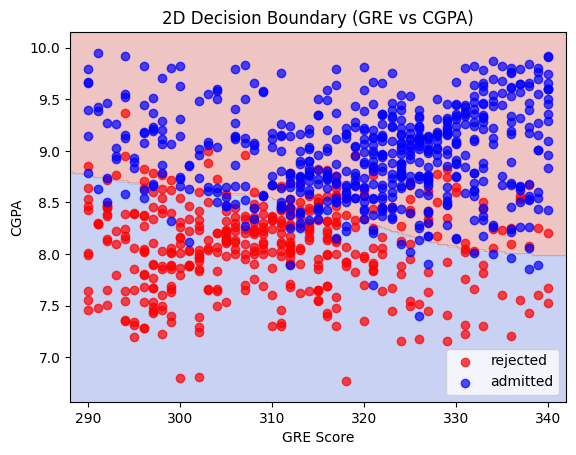

In [5]:
# plot two dimensional decision boundary using support vector machine
x_min, x_max = X_2d[:, 0].min() - 2, X_2d[:, 0].max() + 2
y_min, y_max = X_2d[:, 1].min() - 0.2, X_2d[:, 1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
z = model_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure()
plt.contourf(xx, yy, z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_2d[y == 0, 0], X_2d[y == 0, 1], color='red', label='rejected', alpha=0.7)
plt.scatter(X_2d[y == 1, 0], X_2d[y == 1, 1], color='blue', label='admitted', alpha=0.7)
plt.title('2D Decision Boundary (GRE vs CGPA)')
plt.xlabel('GRE Score')
plt.ylabel('CGPA')
plt.legend()
plt.show()

In [6]:
# train random forest classifier for complex non linear boundary
rf_2d = RandomForestClassifier(n_estimators=100, random_state=42)
rf_2d.fit(X_2d, y)
print('random forest accuracy:', rf_2d.score(X_2d, y))

random forest accuracy: 0.983


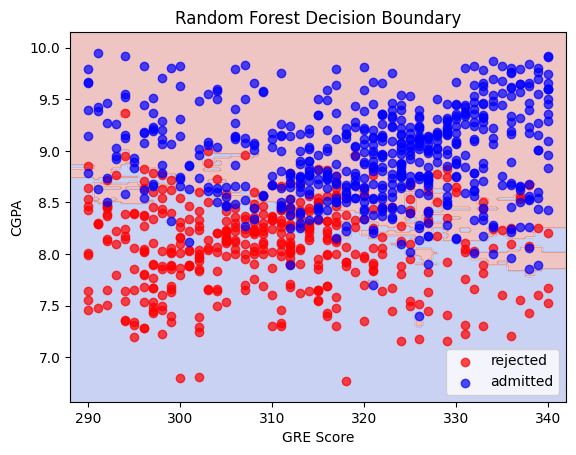

In [7]:
# plot two dimensional decision boundary using random forest
z_rf = rf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure()
plt.contourf(xx, yy, z_rf, alpha=0.3, cmap='coolwarm')
plt.scatter(X_2d[y == 0, 0], X_2d[y == 0, 1], color='red', label='rejected', alpha=0.7)
plt.scatter(X_2d[y == 1, 0], X_2d[y == 1, 1], color='blue', label='admitted', alpha=0.7)
plt.title('Random Forest Decision Boundary')
plt.xlabel('GRE Score')
plt.ylabel('CGPA')
plt.legend()
plt.show()

In [8]:
# train classification model on three features for three dimensional visualization
features_3d = ['GRE Score', 'TOEFL Score', 'CGPA']
X_3d = df[features_3d].values
model_3d = LogisticRegression()
model_3d.fit(X_3d, y)
print('3d model accuracy:', model_3d.score(X_3d, y))

3d model accuracy: 0.889


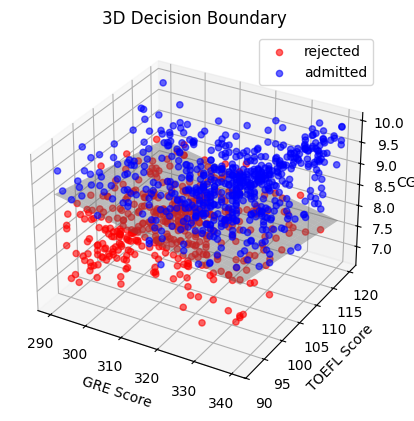

In [9]:
# plot three dimensional decision boundary separating applicants
w = model_3d.coef_[0]
b = model_3d.intercept_[0]

x1_grid, x2_grid = np.meshgrid(
    np.linspace(X_3d[:, 0].min(), X_3d[:, 0].max(), 20),
    np.linspace(X_3d[:, 1].min(), X_3d[:, 1].max(), 20)
)
x3_plane = -(w[0] * x1_grid + w[1] * x2_grid + b) / w[2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_3d[y == 0, 0], X_3d[y == 0, 1], X_3d[y == 0, 2], color='red', label='rejected', alpha=0.6)
ax.scatter(X_3d[y == 1, 0], X_3d[y == 1, 1], X_3d[y == 1, 2], color='blue', label='admitted', alpha=0.6)
ax.plot_surface(x1_grid, x2_grid, x3_plane, color='gray', alpha=0.4)
ax.set_xlabel('GRE Score')
ax.set_ylabel('TOEFL Score')
ax.set_zlabel('CGPA')
ax.set_title('3D Decision Boundary')
ax.legend()
plt.show()